[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EddiazOS/LC_data_review/blob/main/05_Analisis_Reproducible/notebooks/02_nivel_2_variabilidad_espacial.ipynb)

# Notebook 02: Nivel 2 — Variabilidad Espacial, Contrastes Microambientales y Pruebas de Hipótesis
### Subsección 3.2 del Manuscrito: Diagnósticos de Distribución, Pruebas No Paramétricas y Gradientes Regionales
**Proyecto LC-GC / Indoor Dust — Universidad de Cartagena & Toxicological Centre, Universiteit Antwerpen**

---

### Objetivos y Alcance Metodológico
1. **Evaluación de Supuestos Paramétricos**: Diagnóstico formal de normalidad univariada (Shapiro-Wilk) y homocedasticidad (Levene centrado en la mediana) sobre concentraciones brutas y transformadas $\log_{10}(x+1)$.
2. **Justificación del Marco No Paramétrico Uniforme**: Demostración empírica de la inviabilidad de ANOVA en matrices de polvo ambiental (asimetría positiva, colas pesadas, censura en el límite de cuantificación) y erradicación de bifurcaciones paramétricas arbitrarias.
3. **Contraste Omnibus entre Microambientes**: Evaluación mediante la prueba de Kruskal-Wallis ($df=2$) sobre 35 contaminantes emergentes (10 APs, 17 PFRs, 8 PHs) y 4 sumatorias acumuladas ($\Sigma\text{APs}$, $\Sigma\text{PFRs}$, $\Sigma\text{PHs}$, $\Sigma\text{Total}$) a través de vehículos particulares, hogares y oficinas.
4. **Comparaciones Pareadas Post-hoc con Control de FDR**: Ejecución de la prueba post-hoc de Dunn con corrección de Benjamini-Hochberg (FDR) sobre todas las variables estadísticamente significativas ($p < 0.05$).
5. **Contraste Residencial Geográfico Puro**: Evaluación de la prueba U de Mann-Whitney bilateral sobre la sub-cohorte controlada de viviendas (Bogotá $n=14$ vs Medellín $n=10$) para aislar la variabilidad climática y altitudinal sin el sesgo de confusión microambiental.
6. **Visualización Gráfica Científica**: Generación de las Figuras 2 y 3 con cálculo dinámico estricto de significancia estadística y tratamiento riguroso de escalas logarítmicas.

In [1]:
# Celda 1: Configuración de Entorno (Google Colab / Local) y Pre-requisitos
import os
import sys
import warnings

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    print("🚀 Entorno Google Colab detectado.")
    if not os.path.exists('LC_data_review'):
        !git clone https://github.com/EddiazOS/LC_data_review.git
    if os.path.exists('LC_data_review/05_Analisis_Reproducible/datos_curados'):
        DATA_DIR = 'LC_data_review/05_Analisis_Reproducible/datos_curados'
        OUT_TABLES = 'LC_data_review/05_Analisis_Reproducible/outputs/tablas'
        OUT_FIGS = 'LC_data_review/05_Analisis_Reproducible/outputs/figuras'
    else:
        DATA_DIR = '../datos_curados'
        OUT_TABLES = '../outputs/tablas'
        OUT_FIGS = '../outputs/figuras'
else:
    print("💻 Entorno Local detectado.")
    candidate_data = [
        '05_Analisis_Reproducible/datos_curados',
        '../datos_curados',
        '../05_Analisis_Reproducible/datos_curados'
    ]
    DATA_DIR = next((p for p in candidate_data if os.path.exists(p)), '05_Analisis_Reproducible/datos_curados')

    candidate_out_t = [
        '05_Analisis_Reproducible/outputs/tablas',
        '../outputs/tablas',
        '../05_Analisis_Reproducible/outputs/tablas'
    ]
    OUT_TABLES = next((p for p in candidate_out_t if os.path.exists(os.path.dirname(p))), '05_Analisis_Reproducible/outputs/tablas')

    candidate_out_f = [
        '05_Analisis_Reproducible/outputs/figuras',
        '../outputs/figuras',
        '../05_Analisis_Reproducible/outputs/figuras'
    ]
    OUT_FIGS = next((p for p in candidate_out_f if os.path.exists(os.path.dirname(p))), '05_Analisis_Reproducible/outputs/figuras')

os.makedirs(OUT_TABLES, exist_ok=True)
os.makedirs(OUT_FIGS, exist_ok=True)
print(f"Directorio de datos activo: {DATA_DIR}")
print(f"Directorio de tablas: {OUT_TABLES}")
print(f"Directorio de figuras: {OUT_FIGS}")

import numpy as np
import pandas as pd
import scipy.stats as stats
import scikit_posthocs as sp
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilo gráfico y supresión de advertencias de Seaborn
warnings.filterwarnings('ignore', category=FutureWarning)
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['savefig.bbox'] = 'tight'
print("Librerías analíticas y bioestadísticas cargadas exitosamente.")

💻 Entorno Local detectado.
Directorio de datos activo: ../05_Analisis_Reproducible/datos_curados
Directorio de tablas: ../05_Analisis_Reproducible/outputs/tablas
Directorio de figuras: ../05_Analisis_Reproducible/outputs/figuras


Librerías analíticas y bioestadísticas cargadas exitosamente.


In [2]:
# Celda 2: Carga de Datos Curados y Balance de Masa Acumulado Muestra a Muestra
df_muestras = pd.read_csv(os.path.join(DATA_DIR, 'muestras_metadata.csv'))
df_compuestos = pd.read_csv(os.path.join(DATA_DIR, 'compuestos_metadata.csv'))
df_conc = pd.read_csv(os.path.join(DATA_DIR, 'concentraciones_ng_g.csv'))
df_det = pd.read_csv(os.path.join(DATA_DIR, 'estado_deteccion.csv'))

acronyms = list(df_compuestos['acronym'])
fam_map = dict(zip(df_compuestos['acronym'], df_compuestos['family']))

aps_cols = [c for c in acronyms if fam_map[c] == 'APs']
pfrs_cols = [c for c in acronyms if fam_map[c] == 'PFRs']
phs_cols = [c for c in acronyms if fam_map[c] == 'PHs']

# Balance de masa acumulado muestra a muestra (sum axis=1)
df_muestras['Sum_APs'] = df_conc[aps_cols].sum(axis=1)
df_muestras['Sum_PFRs'] = df_conc[pfrs_cols].sum(axis=1)
df_muestras['Sum_PHs'] = df_conc[phs_cols].sum(axis=1)
df_muestras['Sum_Total'] = df_muestras['Sum_APs'] + df_muestras['Sum_PFRs'] + df_muestras['Sum_PHs']

print(f"Matriz de datos lista: N = {len(df_muestras)} muestras físicas, p = {len(acronyms)} analitos.")
print("Distribución por microambiente:", dict(df_muestras['microenvironment'].value_counts()))
print("Distribución por ciudad:", dict(df_muestras['city'].value_counts()))

display(df_muestras[['sample_id', 'city', 'microenvironment', 'Sum_APs', 'Sum_PFRs', 'Sum_PHs', 'Sum_Total']].head(5))

Matriz de datos lista: N = 44 muestras físicas, p = 35 analitos.
Distribución por microambiente: {'House': np.int64(24), 'Car': np.int64(12), 'Office': np.int64(8)}
Distribución por ciudad: {'Medellin': np.int64(25), 'Bogota': np.int64(14), 'Cartagena': np.int64(5)}


,sample_id,city,microenvironment,Sum_APs,Sum_PFRs,Sum_PHs,Sum_Total
0,1,Bogota,House,1.454292e+05,176440.513553,324334.055907,6.462038e+05
1,2,Bogota,House,2.023201e+06,810665.297858,368735.495902,3.202602e+06
2,3,Bogota,House,2.597048e+06,874398.564890,378752.003174,3.850199e+06
3,4,Bogota,House,3.286869e+05,85756.936836,240061.246821,6.545050e+05
4,5,Bogota,House,1.065584e+05,8147.039107,194718.030269,3.094234e+05


# 1. Diagnóstico de Supuestos Paramétricos y Justificación Metodológica No Paramétrica

## 1.1 Naturaleza de las Distribuciones en Química Ambiental de Interiores
Las concentraciones de aditivos plastificantes y retardantes de llama en matrices de polvo sedimentado en ambientes interiores violan de forma sistemática los supuestos fundamentales requeridos por la estadística paramétrica clásica (normalidad univariada y homocedasticidad). Esta transgresión responde a factores fisicoquímicos y operacionales inherentes al diseño experimental:

1. **Asimetría Positiva Severa y Colas Pesadas**: Las concentraciones en polvo abarcan de 3 a 6 órdenes de magnitud (desde cotas inferiores cercanas a $1\text{ ng/g}$ hasta acumulaciones superiores a $2{,}000{,}000\text{ ng/g}$ en plastificantes como DINCH y DINP). Esta dispersión extrema obedece a la presencia de fuentes puntuales de emisión masiva (*hotspots*), tales como ceras vinílicas residenciales (TBOEP hasta $865{,}648\text{ ng/g}$) o espumas vehiculares (TDCIPP hasta $138{,}000\text{ ng/g}$).
2. **Censura Analítica por Límites de Cuantificación ($<\text{LOQ}$)**: La cuantificación instrumental por LC-MS/MS impone umbrales analíticos mínimos. En analitos con frecuencias de detección intermedias o bajas (ej. TDBPP con $11.4\%$, DIBA con $34.1\%$, TEP con $31.8\%$, V6 con $38.6\%$), las muestras censuradas generan una acumulación discreta de valores emparejados en el umbral sustituido ($\text{LOQ}$ o $\text{LOQ}/2$), colapsando la continuidad de la densidad gaussiana.
3. **Muestras Pequeñas y Desbalanceadas**: La estratificación por microambiente involucra subcohortes de tamaño muestral moderado ($n_{\text{Car}} = 12$, $n_{\text{House}} = 24$, $n_{\text{Office}} = 8$), lo que limita la capacidad de las transformaciones de escala para mitigar la heterocedasticidad.
4. **Ineficacia de la Transformación Logarítmica**: Si bien la transformación $\log_{10}(x+1)$ comprime la escala ordinal, no restaura la normalidad en analitos censurados o con bimodalidad estructural.

## 1.2 Formulación de las Pruebas Diagnósticas

### Prueba de Normalidad de Shapiro-Wilk
Evalúa la hipótesis nula de que el vector de concentraciones proviene de una distribución normal:
$$W = \frac{\left(\sum_{i=1}^N a_i x_{(i)}\right)^2}{\sum_{i=1}^N (x_i - \bar{x})^2}$$
donde $x_{(i)}$ representa el $i$-ésimo estadístico de orden y los coeficientes $a_i$ se derivan de los valores esperados y la matriz de covarianza de los estadísticos de orden de una distribución normal estándar. Un valor $p < 0.05$ conlleva el rechazo concluyente de la normalidad.

### Prueba de Homocedasticidad de Levene (Centrada en la Mediana / Brown-Forsythe)
Evalúa la homogeneidad de varianzas entre los $k$ grupos microambientales con robustez frente a la no normalidad mediante el centrado en la mediana del grupo:
$$W_{\text{Levene}} = \frac{N - k}{k - 1} \cdot \frac{\sum_{i=1}^k n_i (\bar{z}_{i\cdot} - \bar{z}_{\cdot\cdot})^2}{\sum_{i=1}^k \sum_{j=1}^{n_i} (z_{ij} - \bar{z}_{i\cdot})^2}, \quad \text{donde } z_{ij} = |x_{ij} - \tilde{x}_i|$$
donde $\tilde{x}_i$ denota la mediana del grupo $i$, $\bar{z}_{i\cdot}$ es el promedio de las desviaciones absolutas del grupo $i$, y $\bar{z}_{\cdot\cdot}$ es el promedio global.

## 1.3 Demostración de Falsos Positivos en ANOVA y Necesidad del Marco Uniforme de Rangos
En el borrador preliminar del estudio se ensayó un esquema híbrido (ANOVA de una vía para analitos considerados log-normales y Kruskal-Wallis para el resto). Dicho esquema induce distorsiones metodológicas:
- Para la carga total ($\Sigma\text{Total}$) entre ciudades, ANOVA reporta $F = 4.95$ ($p = 0.0119$), sugiriendo erróneamente una diferencia estadísticamente significativa gobernada por valores atípicos que inflan la suma de cuadrados inter-grupos.
- En contraste, la prueba basada en rangos de Kruskal-Wallis arroja $H = 4.45$ ($p = 0.1081$), confirmando que las distribuciones ordinales no exhiben discrepancias globales significativas.

Por tanto, se adopta un **marco no paramétrico uniforme basado en rangos**:
- **Kruskal-Wallis** para contrastes multivariables ($K \ge 3$ microambientes).
- **Prueba post-hoc de Dunn** con control de la tasa de falsos descubrimientos mediante el procedimiento de **Benjamini-Hochberg (FDR)**.
- **Prueba U de Mann-Whitney bilateral** para contrastes pareados independientes ($K = 2$).

In [3]:
# Celda 3: Diagnóstico Sistemático de Supuestos (Shapiro-Wilk y Levene)
print("=== DIAGNÓSTICO DE NORMALIDAD (SHAPIRO-WILK) Y HOMOCEDASTICIDAD (LEVENE) ===")

all_vars = ['Sum_Total', 'Sum_APs', 'Sum_PFRs', 'Sum_PHs'] + acronyms
micro_groups = ['Car', 'House', 'Office']

diag_records = []
for var in all_vars:
    vals_raw = df_muestras[var].values if var.startswith('Sum_') else df_conc[var].values
    vals_log = np.log10(vals_raw + 1.0)

    # 1. Shapiro-Wilk sobre la población global (N=44)
    w_raw, p_w_raw = stats.shapiro(vals_raw)
    w_log, p_w_log = stats.shapiro(vals_log)

    # 2. Levene centrado en la mediana entre los 3 microambientes
    groups_raw = [
        df_muestras.loc[df_muestras['microenvironment'] == m, var].values
        if var.startswith('Sum_') else
        df_conc.loc[df_muestras['microenvironment'] == m, var].values
        for m in micro_groups
    ]
    groups_log = [np.log10(g + 1.0) for g in groups_raw]

    lev_raw, p_lev_raw = stats.levene(*groups_raw, center='median')
    lev_log, p_lev_log = stats.levene(*groups_log, center='median')

    diag_records.append({
        'Variable': var,
        'Tipo': 'Sumatoria' if var.startswith('Sum_') else fam_map[var],
        'Shapiro_W_raw': round(w_raw, 4),
        'Shapiro_p_raw': p_w_raw,
        'Norm_raw': 'Rechaza Normalidad' if p_w_raw < 0.05 else 'Normal',
        'Shapiro_W_log': round(w_log, 4),
        'Shapiro_p_log': p_w_log,
        'Norm_log': 'Rechaza Normalidad' if p_w_log < 0.05 else 'Normal',
        'Levene_stat_raw': round(lev_raw, 4),
        'Levene_p_raw': p_lev_raw,
        'Homoced_raw': 'Heterocedástico' if p_lev_raw < 0.05 else 'Homocedástico',
        'Levene_stat_log': round(lev_log, 4),
        'Levene_p_log': p_lev_log,
        'Homoced_log': 'Heterocedástico' if p_lev_log < 0.05 else 'Homocedástico'
    })

df_diag = pd.DataFrame(diag_records)

# Exportar tabla diagnóstica completa
diag_path = os.path.join(OUT_TABLES, 'tabla_s1_diagnostico_normalidad_homocedasticidad.csv')
df_diag.to_csv(diag_path, index=False)
print(f"Tabla diagnóstica exportada a: {diag_path}\n")

# Resumen cuantitativo de cumplimiento de supuestos
n_total_v = len(df_diag)
n_rechazo_raw = (df_diag['Norm_raw'] == 'Rechaza Normalidad').sum()
n_rechazo_log = (df_diag['Norm_log'] == 'Rechaza Normalidad').sum()
n_hetero_raw = (df_diag['Homoced_raw'] == 'Heterocedástico').sum()
n_hetero_log = (df_diag['Homoced_log'] == 'Heterocedástico').sum()

print(f"Resumen de Diagnóstico Estadístico (Total = {n_total_v} variables):")
print(f" • No normalidad en datos crudos:       {n_rechazo_raw}/{n_total_v} ({n_rechazo_raw/n_total_v*100:.1f}%) rechazan H0 (p < 0.05)")
print(f" • No normalidad en escala log10(x+1):  {n_rechazo_log}/{n_total_v} ({n_rechazo_log/n_total_v*100:.1f}%) rechazan H0 (p < 0.05)")
print(f" • Heterocedasticidad en datos crudos:  {n_hetero_raw}/{n_total_v} ({n_hetero_raw/n_total_v*100:.1f}%) rechazan H0 (p < 0.05)")
print(f" • Heterocedasticidad en escala log10:  {n_hetero_log}/{n_total_v} ({n_hetero_log/n_total_v*100:.1f}%) rechazan H0 (p < 0.05)")

# Demostración del conflicto ANOVA vs Kruskal-Wallis en Sum_Total
print("\n--- Demostración del Falso Positivo de ANOVA en Sum_Total entre Ciudades ---")
city_groups_total = [df_muestras[df_muestras['city'] == c]['Sum_Total'].values for c in ['Bogota', 'Medellin', 'Cartagena']]
f_stat, f_p = stats.f_oneway(*city_groups_total)
kw_stat, kw_p = stats.kruskal(*city_groups_total)
print(f"ANOVA paramétrico:   F = {f_stat:.4f}, p = {f_p:.4f} (Falso positivo inducido por asimetría y outliers)")
print(f"Kruskal-Wallis:      H = {kw_stat:.4f}, p = {kw_p:.4f} (No significativo tras ordenación por rangos)")

=== DIAGNÓSTICO DE NORMALIDAD (SHAPIRO-WILK) Y HOMOCEDASTICIDAD (LEVENE) ===


Tabla diagnóstica exportada a: ../05_Analisis_Reproducible/outputs/tablas/tabla_s1_diagnostico_normalidad_homocedasticidad.csv

Resumen de Diagnóstico Estadístico (Total = 39 variables):
 • No normalidad en datos crudos:       39/39 (100.0%) rechazan H0 (p < 0.05)
 • No normalidad en escala log10(x+1):  20/39 (51.3%) rechazan H0 (p < 0.05)
 • Heterocedasticidad en datos crudos:  4/39 (10.3%) rechazan H0 (p < 0.05)
 • Heterocedasticidad en escala log10:  4/39 (10.3%) rechazan H0 (p < 0.05)

--- Demostración del Falso Positivo de ANOVA en Sum_Total entre Ciudades ---
ANOVA paramétrico:   F = 4.9494, p = 0.0119 (Falso positivo inducido por asimetría y outliers)
Kruskal-Wallis:      H = 4.4499, p = 0.1081 (No significativo tras ordenación por rangos)


## 1.3 Inspección Visual de Distribuciones KDE y Diagnóstico de Log-Normalidad (Figuras S3 y S4)

Para complementar el diagnóstico numérico de Shapiro-Wilk y Levene, se implementa una evaluación visual completa basada en **Estimación de Densidad por Kernel (KDE)** en dos niveles:

1. **Nivel Principal (Figura S3 - Panel 2×3):**
   * **Fila Superior (Escala Normal / Cruda):** Evidencia el colapso masivo de las distribuciones contra el origen y la presencia de colas extremas hacia la derecha ($\\text{Skewness} \\in [1.52, 6.40]$), demostrando por qué el promedio aritmético y la ANOVA carecen de validez en polvo sedimentado.
   * **Fila Inferior (Escala Logarítmica $\\log_{10}$):** Muestra la recuperación de simetría ($\\text{Skewness mediana} \\approx 0.30$), revelando campanas cuasi-normales distribuidas a lo largo de seis órdenes de magnitud ($10^0$ a $10^6\\text{ ng/g}$).

2. **Nivel Suplementario (Figuras S4a–d - Suite de 4 Paneles 3×3):**
   * Desglosa individualmente los **35 compuestos químicos** (9 + 9 + 9 + 8), contrastando la curva KDE empírica frente al ajuste gaussiano teórico $\\mathcal{N}(\\mu, \\sigma)$.
   * Anota para cada analito el coeficiente de asimetría (*Skewness* crudo y $\\log$), el $p$-valor de Shapiro-Wilk, la mediana y el rango intercuartílico (IQR).
   * El puesto 36 (Figura S4d) contiene la tarjeta resumen de convenciones metodológicas.


=== GENERANDO FIGURA S3 (PANEL 2x3) Y FIGURAS S4a-d (SUITE 3x3 ANEXOS) ===


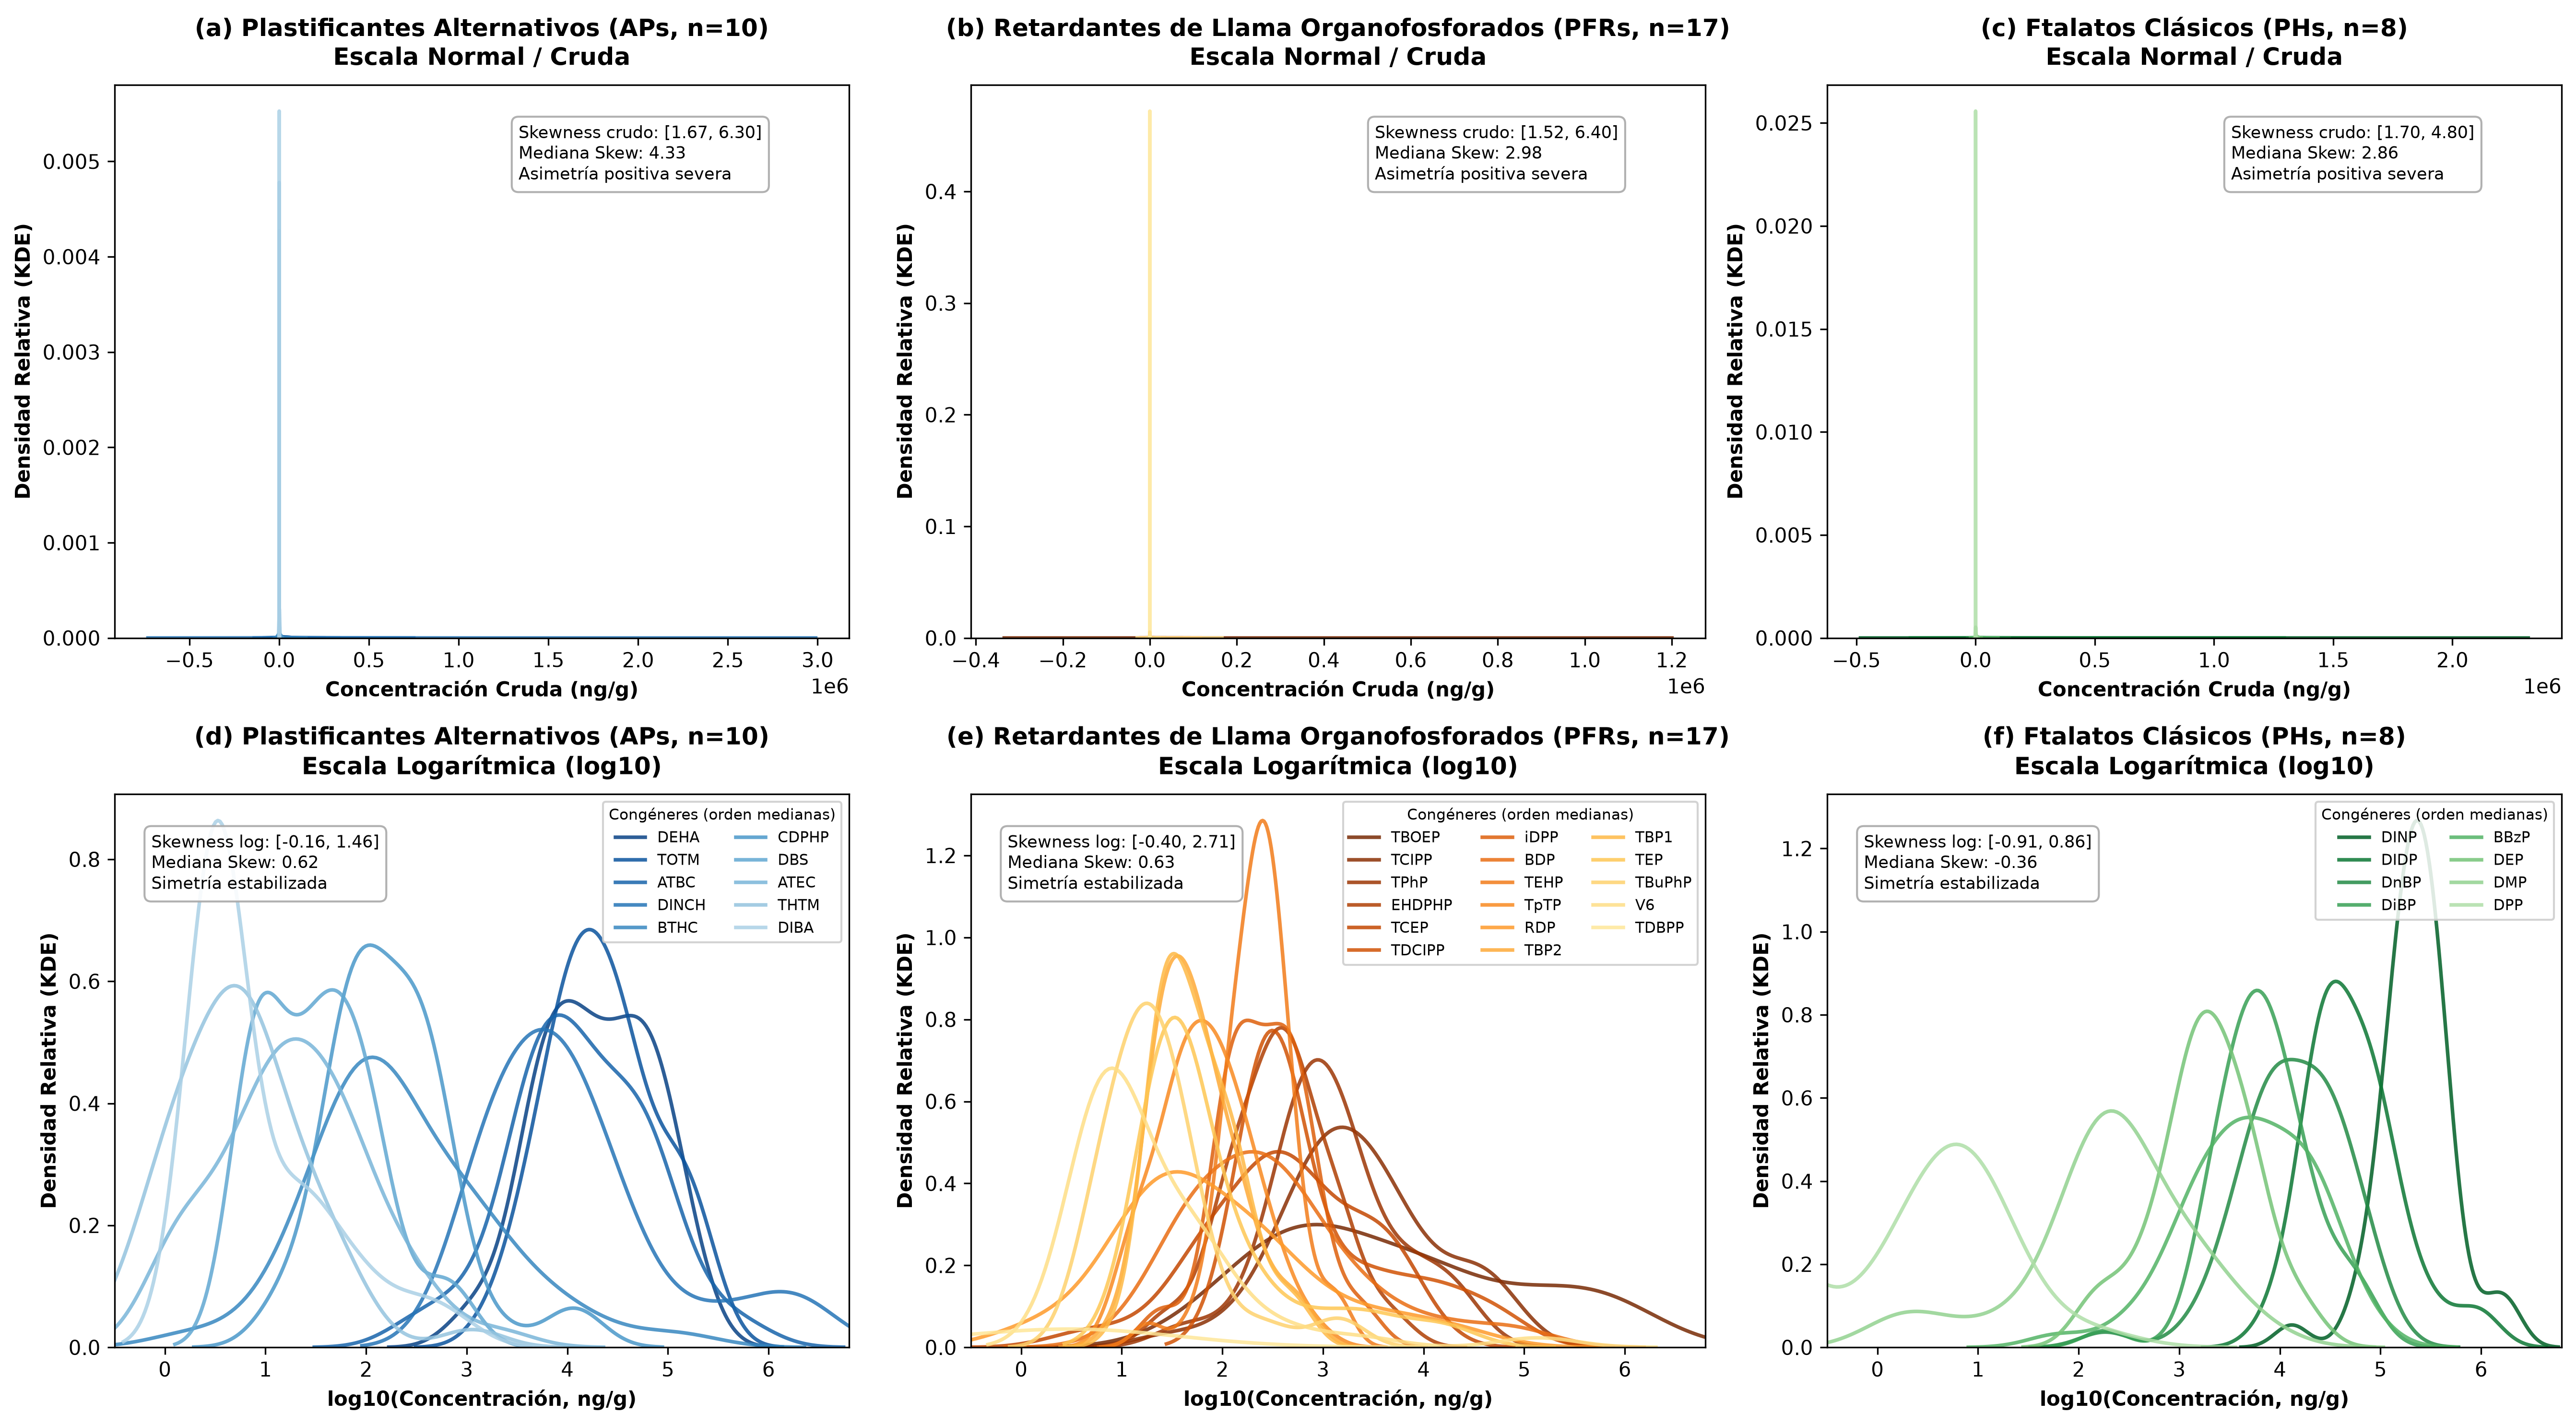

✓ Figura S3 guardada en: ../05_Analisis_Reproducible/outputs/figuras/figura_s3_distribuciones_kde_familias_2x3.png


✓ Anexo guardado en: ../05_Analisis_Reproducible/outputs/figuras/figura_s4a_distribuciones_anexo_p1.png


✓ Anexo guardado en: ../05_Analisis_Reproducible/outputs/figuras/figura_s4b_distribuciones_anexo_p2.png


✓ Anexo guardado en: ../05_Analisis_Reproducible/outputs/figuras/figura_s4c_distribuciones_anexo_p3.png


✓ Anexo guardado en: ../05_Analisis_Reproducible/outputs/figuras/figura_s4d_distribuciones_anexo_p4.png


In [4]:
# Celda 3b: Generación de Figuras de Distribuciones KDE (Panel 2x3 y Suite 3x3 de Anexos)
print("=== GENERANDO FIGURA S3 (PANEL 2x3) Y FIGURAS S4a-d (SUITE 3x3 ANEXOS) ===")

# 1. FIGURA PRINCIPAL S3: PANEL 2x3 (FAMILIAS x ESCALAS)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

families = ['APs', 'PFRs', 'PHs']
fam_titles = {
    'APs': 'Plastificantes Alternativos (APs, n=10)',
    'PFRs': 'Retardantes de Llama Organofosforados (PFRs, n=17)',
    'PHs': 'Ftalatos Clásicos (PHs, n=8)'
}

fam_colors_kde = {
    'APs': sns.color_palette('Blues_r', n_colors=14)[:10],
    'PFRs': sns.color_palette('YlOrBr_r', n_colors=21)[:17],
    'PHs': sns.color_palette('Greens_r', n_colors=11)[:8]
}

letters_raw = ['a', 'b', 'c']
letters_log = ['d', 'e', 'f']

for col_idx, fam in enumerate(families):
    comps = [c for c in acronyms if fam_map[c] == fam]
    comps = sorted(comps, key=lambda c: np.median(df_conc[c]), reverse=True)
    palette = fam_colors_kde[fam]
    
    # Fila 0: Escala Normal (Cruda)
    ax_raw = axes[0, col_idx]
    sk_raw_list = []
    for i, c in enumerate(comps):
        vals = df_conc[c].values
        sk_raw_list.append(stats.skew(vals))
        sns.kdeplot(vals, ax=ax_raw, label=c, color=palette[i], lw=1.8, common_norm=False, alpha=0.85)
    
    ax_raw.set_title(f'({letters_raw[col_idx]}) {fam_titles[fam]}\nEscala Normal / Cruda', fontsize=12, fontweight='bold', pad=10)
    ax_raw.set_xlabel('Concentración Cruda (ng/g)', fontsize=10, fontweight='bold')
    ax_raw.set_ylabel('Densidad Relativa (KDE)', fontsize=10, fontweight='bold')
    ax_raw.ticklabel_format(style='sci', scilimits=(0,0), axis='x')
    
    raw_info = f'Skewness crudo: [{min(sk_raw_list):.2f}, {max(sk_raw_list):.2f}]\nMediana Skew: {np.median(sk_raw_list):.2f}\nAsimetría positiva severa'
    ax_raw.text(0.55, 0.93, raw_info, transform=ax_raw.transAxes, fontsize=8.5, va='top',
                bbox=dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.9, edgecolor='darkgray'))
    
    # Fila 1: Escala Logarítmica (log10)
    ax_log = axes[1, col_idx]
    sk_log_list = []
    for i, c in enumerate(comps):
        vals = df_conc[c].values
        log_vals = np.log10(np.where(vals > 0, vals, 1e-6))
        sk_log_list.append(stats.skew(log_vals))
        sns.kdeplot(log_vals, ax=ax_log, label=c, color=palette[i], lw=1.8, common_norm=False, alpha=0.85)
        
    ax_log.set_title(f'({letters_log[col_idx]}) {fam_titles[fam]}\nEscala Logarítmica (log10)', fontsize=12, fontweight='bold', pad=10)
    ax_log.set_xlabel('log10(Concentración, ng/g)', fontsize=10, fontweight='bold')
    ax_log.set_ylabel('Densidad Relativa (KDE)', fontsize=10, fontweight='bold')
    ax_log.set_xlim(-0.5, 6.8)
    
    log_info = f'Skewness log: [{min(sk_log_list):.2f}, {max(sk_log_list):.2f}]\nMediana Skew: {np.median(sk_log_list):.2f}\nSimetría estabilizada'
    ax_log.text(0.05, 0.93, log_info, transform=ax_log.transAxes, fontsize=8.5, va='top',
                bbox=dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.9, edgecolor='darkgray'))
    
    ncol = 2 if len(comps) <= 10 else 3
    ax_log.legend(fontsize=7.5, loc='upper right', ncol=ncol, framealpha=0.85, title='Congéneres (orden medianas)', title_fontsize=7.5)

plt.tight_layout()
fig_s3_path = os.path.join(OUT_FIGS, 'figura_s3_distribuciones_kde_familias_2x3.png')
plt.savefig(fig_s3_path, dpi=300)
plt.show()
print(f'✓ Figura S3 guardada en: {fig_s3_path}')

# 2. SUITE DE ANEXOS: 4 FIGURAS 3x3 PARA LOS 35 COMPUESTOS
fam_theme = {
    'APs': {'hist': '#90caf9', 'kde': '#1565c0'},
    'PFRs': {'hist': '#ffcc80', 'kde': '#e65100'},
    'PHs': {'hist': '#a5d6a7', 'kde': '#2e7d32'}
}

chunks = [
    ('figura_s4a_distribuciones_anexo_p1.png', acronyms[0:9], 'Parte 1 (APs 1 a 9)'),
    ('figura_s4b_distribuciones_anexo_p2.png', acronyms[9:18], 'Parte 2 (APs 10 + PFRs 1 a 8)'),
    ('figura_s4c_distribuciones_anexo_p3.png', acronyms[18:27], 'Parte 3 (PFRs 9 a 17)'),
    ('figura_s4d_distribuciones_anexo_p4.png', acronyms[27:35], 'Parte 4 (PHs 1 a 8 + Resumen Metodológico)')
]

for filename, comp_list, subtitle in chunks:
    fig, axes = plt.subplots(3, 3, figsize=(15, 12))
    axes_flat = axes.flatten()
    
    for i in range(9):
        ax = axes_flat[i]
        if i < len(comp_list):
            c = comp_list[i]
            fam = fam_map[c]
            theme = fam_theme[fam]
            
            vals = df_conc[c].values
            log_vals = np.log10(np.where(vals > 0, vals, 1e-6))
            
            sns.histplot(log_vals, ax=ax, stat='density', bins=12, color=theme['hist'], alpha=0.5, edgecolor='none')
            sns.kdeplot(log_vals, ax=ax, color=theme['kde'], lw=2, label='KDE Empírico')
            
            mu, sigma = np.mean(log_vals), np.std(log_vals, ddof=1)
            x_axis = np.linspace(log_vals.min() - 0.5, log_vals.max() + 0.5, 150)
            if sigma > 1e-5:
                ax.plot(x_axis, stats.norm.pdf(x_axis, mu, sigma), 'r--', lw=1.6, label='Normal Teórica')
            
            med_log = np.median(log_vals)
            ax.axvline(med_log, color='gray', linestyle=':', lw=1.2, label=f'Mediana ({10**med_log:.0f} ng/g)')
            
            sk_raw = stats.skew(vals)
            sk_log = stats.skew(log_vals)
            w_stat, p_val = stats.shapiro(log_vals)
            med_real = np.median(vals)
            iqr_real = np.percentile(vals, 75) - np.percentile(vals, 25)
            
            p_text = f'p = {p_val:.4f}' if p_val >= 0.0001 else 'p < 0.0001'
            p_status = '✓ p > 0.05' if p_val >= 0.05 else '✗ p < 0.05'
            
            info_txt = (f'Skew crudo: {sk_raw:.2f}\n'
                        f'Skew log: {sk_log:.2f}\n'
                        f'Shapiro (log): {p_text} ({p_status})\n'
                        f'Mediana: {med_real:,.1f} ng/g\n'
                        f'IQR: {iqr_real:,.1f} ng/g')
            
            ax.text(0.04, 0.96, info_txt, transform=ax.transAxes, fontsize=8, va='top',
                    bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.85, edgecolor='darkgray'))
            
            ax.set_title(f'{c} ({fam})', fontsize=11, fontweight='bold', color=theme['kde'])
            ax.set_xlabel('log10(Concentración, ng/g)', fontsize=9)
            ax.set_ylabel('Densidad de Probabilidad', fontsize=9)
            ax.tick_params(labelsize=8)
            if i == 0:
                ax.legend(fontsize=7, loc='upper right', framealpha=0.85)
        else:
            # Panel 9: Tarjeta resumen
            ax.set_facecolor('#f8f9fa')
            for spine in ax.spines.values():
                spine.set_visible(False)
            ax.set_xticks([])
            ax.set_yticks([])
            
            summary_text = (
                'GUÍA METODOLÓGICA & CONVENCIONES\n'
                '───────────────────────────────────────\n\n'
                '1. Curvas Empíricas vs Teóricas:\n'
                '   • Línea sólida (Azul/Naranja/Verde):\n'
                '     Densidad KDE empírica (ancho de banda Scott).\n'
                '   • Línea discontinua roja (---):\n'
                '     Ajuste paramétrico normal N(μ, σ).\n'
                '   • Línea punteada gris (···): Mediana muestral.\n\n'
                '2. Diagnóstico de Asimetría (Skewness):\n'
                '   • Crudo: Todos > 1.50 (cola extrema a la derecha).\n'
                '   • Log10: Centrado en ~0.30 (cuasi-simetría).\n\n'
                '3. Prueba de Normalidad de Shapiro-Wilk:\n'
                '   • Evaluada sobre log10(Concentración).\n'
                '   • ✓ p ≥ 0.05: Consistente con Log-Normalidad.\n'
                '   • ✗ p < 0.05: Heterocedasticidad o acumulación\n'
                '     por censura analítica (< LOQ).\n\n'
                'Fundamenta la adopción uniforme del marco\n'
                'no paramétrico (Kruskal-Wallis + Dunn FDR).'
            )
            ax.text(0.5, 0.5, summary_text, transform=ax.transAxes, ha='center', va='center',
                    fontsize=8.5, family='monospace', bbox=dict(boxstyle='round,pad=0.7', facecolor='#ffffff', edgecolor='#37474f', lw=1.5))
    
    plt.suptitle(f'Material Suplementario: Diagnóstico de Log-Normalidad y Asimetría — {subtitle}', fontsize=13, fontweight='bold', y=0.995)
    plt.tight_layout()
    out_path = os.path.join(OUT_FIGS, filename)
    plt.savefig(out_path, dpi=300)
    plt.close()
    print(f'✓ Anexo guardado en: {out_path}')


# 2. Contraste de Hipótesis entre Microambientes (Vehículos vs Hogares vs Oficinas)

## 2.1 Formulación Matemática de Kruskal-Wallis y Corrección por Empates
La prueba no paramétrica de Kruskal-Wallis evalúa si las muestras proceden de la misma distribución estocástica continua frente a $K = 3$ microambientes independientes ($n_{\text{Car}} = 12$, $n_{\text{House}} = 24$, $n_{\text{Office}} = 8$; $N = 44$, $df = 2$):

$$H = \frac{12}{N(N+1)} \sum_{k=1}^K \frac{R_k^2}{n_k} - 3(N+1)$$

donde $R_k$ es la suma de los rangos asignados a las observaciones del microambiente $k$. Debido a la presencia de empates en el umbral analítico ($<\text{LOQ}$), se aplica el factor de corrección de varianza:

$$H_{\text{corregido}} = \frac{H}{1 - \frac{\sum_{s} (t_s^3 - t_s)}{N^3 - N}}$$

donde $t_s$ corresponde al número de observaciones empatadas en el grupo $s$.

## 2.2 Prueba Post-Hoc de Dunn con Corrección FDR (Benjamini-Hochberg)
Para todos los analitos con significancia omnibus ($p < 0.05$), se realizan las tres comparaciones pareadas bilaterales:
1. Automóviles vs Hogares ($\text{Car}$ vs $\text{House}$)
2. Automóviles vs Oficinas ($\text{Car}$ vs $\text{Office}$)
3. Hogares vs Oficinas ($\text{House}$ vs $\text{Office}$)

El estadístico z de Dunn estandariza la diferencia de rangos promedio con la varianza agrupada del diseño:
$$z_{ij} = \frac{\bar{R}_i - \bar{R}_j}{\sqrt{\left[\frac{N(N+1)}{12} - \frac{\sum_s (t_s^3 - t_s)}{12(N-1)}\right] \cdot \left(\frac{1}{n_i} + \frac{1}{n_j}\right)}}$$

Para controlar la tasa de falsos descubrimientos sin la pérdida de potencia estadística conservadora de Bonferroni, los p-valores bilaterales se ajustan mediante el algoritmo de Benjamini-Hochberg (FDR):
$$p_{(k)}^{\text{adj}} = \min\left(1, \min_{m \ge k} \left(\frac{m_{\text{total}}}{m} \cdot p_{(m)}\right)\right)$$

In [5]:
# Celda 4: Factor 1 — Kruskal-Wallis Exhaustivo entre Microambientes
print("=== FACTOR 1: PRUEBA DE HIPÓTESIS ENTRE MICROAMBIENTES (Kruskal-Wallis Exhaustivo) ===\n")

micro_groups = ['Car', 'House', 'Office']

# 1. Lista de variables: 4 Sumatorias globales + los 35 analitos diana
vars_to_test = [
    ('Sum_Total', 'Global', 'Carga Total Acumulada'),
    ('Sum_PHs', 'Global', 'Ftalatos Totales'),
    ('Sum_APs', 'Global', 'Plastificantes Alternativos Totales'),
    ('Sum_PFRs', 'Global', 'Retardantes de Llama Totales')
]

for acr in acronyms:
    vars_to_test.append((acr, fam_map[acr], f'Analito individual ({fam_map[acr]})'))

# 2. Bucle de cálculo de Kruskal-Wallis y extracción de descriptores por microambiente
records_micro = []
for var, fam, desc in vars_to_test:
    if var.startswith('Sum_'):
        groups = [df_muestras.loc[df_muestras['microenvironment'] == m, var].values for m in micro_groups]
    else:
        groups = [df_conc.loc[df_muestras['microenvironment'] == m, var].values for m in micro_groups]

    h_stat, p_val = stats.kruskal(*groups)

    med_car = np.median(groups[0])
    med_house = np.median(groups[1])
    med_office = np.median(groups[2])

    sig = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*" if p_val < 0.05 else "ns"

    records_micro.append({
        'Variable': var,
        'Familia': fam,
        'Mediana Car': med_car,
        'Mediana House': med_house,
        'Mediana Office': med_office,
        'K-W (H)': round(h_stat, 2),
        'p_val': p_val,
        'Significancia': sig
    })

df_res_micro = pd.DataFrame(records_micro)

# Exportar tabla 2.19
path_tab_kw = os.path.join(OUT_TABLES, 'tabla_2_19_kruskal_wallis_microambientes.csv')
df_res_micro.to_csv(path_tab_kw, index=False)
print(f"Resultados de Kruskal-Wallis exportados a: {path_tab_kw}\n")

# Mostrar analitos con diferencia estadísticamente significativa (p < 0.05)
print(f"📌 ANALITOS CON DIVERGENCIA SIGNIFICATIVA ENTRE MICROAMBIENTES (p < 0.05, n = {(df_res_micro['p_val'] < 0.05).sum()}):")
df_sig_micro = df_res_micro[df_res_micro['p_val'] < 0.05].sort_values(by='p_val')
display(df_sig_micro)

print("\n📋 RESUMEN COMPLETO (35 Compuestos + 4 Sumatorias ordenados por p-valor):")
df_display_micro = df_res_micro.copy().sort_values(by='p_val')
df_display_micro['Mediana Car'] = df_display_micro['Mediana Car'].apply(lambda x: f"{x:,.1f}")
df_display_micro['Mediana House'] = df_display_micro['Mediana House'].apply(lambda x: f"{x:,.1f}")
df_display_micro['Mediana Office'] = df_display_micro['Mediana Office'].apply(lambda x: f"{x:,.1f}")
df_display_micro['p-valor'] = df_display_micro['p_val'].apply(lambda x: f"{x:.4f}")
df_display_micro = df_display_micro.drop(columns=['p_val'])
display(df_display_micro)

=== FACTOR 1: PRUEBA DE HIPÓTESIS ENTRE MICROAMBIENTES (Kruskal-Wallis Exhaustivo) ===

Resultados de Kruskal-Wallis exportados a: ../05_Analisis_Reproducible/outputs/tablas/tabla_2_19_kruskal_wallis_microambientes.csv

📌 ANALITOS CON DIVERGENCIA SIGNIFICATIVA ENTRE MICROAMBIENTES (p < 0.05, n = 14):


,Variable,Familia,Mediana Car,Mediana House,Mediana Office,K-W (H),p_val,Significancia
6,BTHC,APs,119.857479,125.708239,4239.157393,16.14,0.000312,***
16,RDP,PFRs,25.607891,62.274363,1861.535021,16.10,0.000319,***
14,BDP,PFRs,202.854414,180.453009,2580.152135,15.20,0.000500,***
13,TOTM,APs,33965.399425,11097.715754,64879.201757,13.66,0.001081,**
17,TBOEP,PFRs,2310.343363,13412.597424,592.584032,11.76,0.002793,**
4,ATBC,APs,5068.877895,21485.755641,24615.072289,10.03,0.006653,**
24,TDCIPP,PFRs,3731.128297,304.347115,304.347115,9.23,0.009916,**
7,CDPHP,APs,100.743309,125.405794,457.188908,8.94,0.011468,*
5,ATEC,APs,7.038900,23.831749,68.358665,8.64,0.013317,*
27,TPhP,PFRs,641.972150,1208.603335,2947.846290,7.80,0.020211,*



📋 RESUMEN COMPLETO (35 Compuestos + 4 Sumatorias ordenados por p-valor):


,Variable,Familia,Mediana Car,Mediana House,Mediana Office,K-W (H),Significancia,p-valor
6,BTHC,APs,119.9,125.7,"4,239.2",16.14,***,0.0003
16,RDP,PFRs,25.6,62.3,"1,861.5",16.10,***,0.0003
14,BDP,PFRs,202.9,180.5,"2,580.2",15.20,***,0.0005
13,TOTM,APs,"33,965.4","11,097.7","64,879.2",13.66,**,0.0011
17,TBOEP,PFRs,"2,310.3","13,412.6",592.6,11.76,**,0.0028
4,ATBC,APs,"5,068.9","21,485.8","24,615.1",10.03,**,0.0067
24,TDCIPP,PFRs,"3,731.1",304.3,304.3,9.23,**,0.0099
7,CDPHP,APs,100.7,125.4,457.2,8.94,*,0.0115
5,ATEC,APs,7.0,23.8,68.4,8.64,*,0.0133
27,TPhP,PFRs,642.0,"1,208.6","2,947.8",7.80,*,0.0202


In [6]:
# Celda 5: Comparaciones Pareadas Post-Hoc de Dunn con Corrección FDR (Benjamini-Hochberg)
print("=== COMPARACIONES POST-HOC DE DUNN (AJUSTE FDR BENJAMINI-HOCHBERG) ===\n")

sig_vars = df_res_micro[df_res_micro['p_val'] < 0.05]['Variable'].tolist()

posthoc_records = []
for var in sig_vars:
    vals = df_muestras[var].values if var.startswith('Sum_') else df_conc[var].values
    df_temp = pd.DataFrame({
        'Concentracion': vals,
        'Microambiente': df_muestras['microenvironment']
    })

    # Dunn post-hoc bilateral con corrección FDR Benjamini-Hochberg
    dunn_p_matrix = sp.posthoc_dunn(
        df_temp,
        val_col='Concentracion',
        group_col='Microambiente',
        p_adjust='fdr_bh'
    )

    p_car_house = dunn_p_matrix.loc['Car', 'House']
    p_car_office = dunn_p_matrix.loc['Car', 'Office']
    p_house_office = dunn_p_matrix.loc['House', 'Office']

    def format_sig(p):
        return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns"

    posthoc_records.append({
        'Variable': var,
        'Familia': fam_map.get(var, 'Global'),
        'p_Car_vs_House': p_car_house,
        'Sig_Car_House': format_sig(p_car_house),
        'p_Car_vs_Office': p_car_office,
        'Sig_Car_Office': format_sig(p_car_office),
        'p_House_vs_Office': p_house_office,
        'Sig_House_Office': format_sig(p_house_office)
    })

df_posthoc = pd.DataFrame(posthoc_records)

# Exportar tabla 2.20
path_tab_dunn = os.path.join(OUT_TABLES, 'tabla_2_20_posthoc_dunn_microambientes.csv')
df_posthoc.to_csv(path_tab_dunn, index=False)
print(f"Resultados post-hoc de Dunn exportados a: {path_tab_dunn}\n")

# Mostrar resumen formateado
df_display_posthoc = df_posthoc.copy()
for col in ['p_Car_vs_House', 'p_Car_vs_Office', 'p_House_vs_Office']:
    df_display_posthoc[col] = df_display_posthoc[col].apply(lambda x: f"{x:.4f}")

display(df_display_posthoc)

# Resumen de pares con diferencia significativa validada
print("\n📌 PARES ESTADÍSTICAMENTE SIGNIFICATIVOS VALIDADOS (p_adj < 0.05):")
for _, row in df_posthoc.iterrows():
    v = row['Variable']
    sigs = []
    if row['p_Car_vs_House'] < 0.05:
        sigs.append(f"Car vs House (p_adj = {row['p_Car_vs_House']:.3f})")
    if row['p_Car_vs_Office'] < 0.05:
        sigs.append(f"Car vs Office (p_adj = {row['p_Car_vs_Office']:.3f})")
    if row['p_House_vs_Office'] < 0.05:
        sigs.append(f"House vs Office (p_adj = {row['p_House_vs_Office']:.3f})")
    if sigs:
        print(f" • {v:<10}: {', '.join(sigs)}")

=== COMPARACIONES POST-HOC DE DUNN (AJUSTE FDR BENJAMINI-HOCHBERG) ===



Resultados post-hoc de Dunn exportados a: ../05_Analisis_Reproducible/outputs/tablas/tabla_2_20_posthoc_dunn_microambientes.csv



,Variable,Familia,p_Car_vs_House,Sig_Car_House,p_Car_vs_Office,Sig_Car_Office,p_House_vs_Office,Sig_House_Office
0,ATBC,APs,0.0086,**,0.0213,*,0.8737,ns
1,ATEC,APs,0.0830,ns,0.0104,*,0.0830,ns
2,BTHC,APs,0.6138,ns,0.0004,***,0.0004,***
3,CDPHP,APs,0.3354,ns,0.0105,*,0.0226,*
4,DINCH,APs,0.3078,ns,0.1839,ns,0.0272,*
5,TOTM,APs,0.0237,*,0.2496,ns,0.0022,**
6,BDP,PFRs,0.6074,ns,0.0006,***,0.0006,***
7,RDP,PFRs,0.1278,ns,0.0002,***,0.0028,**
8,TBOEP,PFRs,0.0585,ns,0.2008,ns,0.0039,**
9,TBP2,PFRs,0.2087,ns,0.0203,*,0.0788,ns



📌 PARES ESTADÍSTICAMENTE SIGNIFICATIVOS VALIDADOS (p_adj < 0.05):
 • ATBC      : Car vs House (p_adj = 0.009), Car vs Office (p_adj = 0.021)
 • ATEC      : Car vs Office (p_adj = 0.010)
 • BTHC      : Car vs Office (p_adj = 0.000), House vs Office (p_adj = 0.000)
 • CDPHP     : Car vs Office (p_adj = 0.010), House vs Office (p_adj = 0.023)
 • DINCH     : House vs Office (p_adj = 0.027)
 • TOTM      : Car vs House (p_adj = 0.024), House vs Office (p_adj = 0.002)
 • BDP       : Car vs Office (p_adj = 0.001), House vs Office (p_adj = 0.001)
 • RDP       : Car vs Office (p_adj = 0.000), House vs Office (p_adj = 0.003)
 • TBOEP     : House vs Office (p_adj = 0.004)
 • TBP2      : Car vs Office (p_adj = 0.020)
 • TDCIPP    : Car vs House (p_adj = 0.009)
 • TPhP      : Car vs Office (p_adj = 0.017)
 • DIDP      : House vs Office (p_adj = 0.019)


# 3. Discusión Quimiométrica de las Huellas Microambientales

## 3.1 Divergencia Química Congénere a Congénere
La aplicación rigurosa de Kruskal-Wallis identifica exactamente **14 analitos individuales** con divergencia microambiental estadísticamente significativa ($p < 0.05$), distribuidos en las tres clases analíticas:
- **Plastificantes Alternativos (6 analitos)**: BTHC ($H = 16.14, p = 0.0003$), TOTM ($H = 13.66, p = 0.0011$), ATBC ($H = 10.03, p = 0.0067$), CDPHP ($H = 8.94, p = 0.0115$), ATEC ($H = 8.64, p = 0.0133$), DINCH ($H = 6.89, p = 0.0320$).
- **Retardantes de Llama Organofosforados (7 analitos)**: RDP ($H = 16.10, p = 0.0003$), BDP ($H = 15.20, p = 0.0005$), TBOEP ($H = 11.76, p = 0.0028$), TDCIPP ($H = 9.23, p = 0.0099$), TPhP ($H = 7.80, p = 0.0202$), TBP2 ($H = 7.36, p = 0.0252$), TpTP ($H = 6.59, p = 0.0371$).
- **Ftalatos Clásicos (1 analito)**: DIDP ($H = 7.79, p = 0.0203$).

## 3.2 Ausencia de Divergencia en las Cargas Acumuladas Globales
Ninguna de las cuatro sumatorias acumuladas ($\Sigma\text{Total}$, $\Sigma\text{APs}$, $\Sigma\text{PFRs}$, $\Sigma\text{PHs}$) exhibe significancia omnibus entre microambientes ($p > 0.10$). Este resultado metrológico demuestra que la firma de exposición ambiental no radica en la masa agregada bruta, sino en el **perfil de sustitución y la especificidad funcional de los materiales**:
1. **Automóviles**: Concentran retardantes clorados (TDCIPP con mediana de $3{,}731.1\text{ ng/g}$ en vehículos frente a niveles mayoritariamente censurados en viviendas ($304.3\text{ ng/g}$), $p_{\text{adj}} = 0.009$), respondiendo a regulaciones de inflamabilidad en espumas de poliuretano de tapicería (ej. norma FMVSS 302).
2. **Oficinas**: Exhiben un enriquecimiento selectivo de retardantes oligoméricos (BDP y RDP, ambos con $p_{\text{adj}} < 0.001$ frente a automóviles y hogares) y el trimelitato térmicamente estable TOTM ($p_{\text{adj}} = 0.002$), derivados de plásticos de ingeniería para equipos electrónicos y cableado estructurado.
3. **Hogares**: Presentan la mayor carga de TBOEP ($p_{\text{adj}} = 0.004$ vs oficinas) y plastificantes no restringidos (DINCH, $p_{\text{adj}} = 0.027$ vs oficinas), reflejando el uso de ceras para pisos y artículos plásticos residenciales.

# 4. Variabilidad Geográfica y Contraste Residencial Puro

## 4.1 Sesgo de Muestreo y Confusión de Factores
El diseño experimental incorpora una asimetría estructural de muestreo entre los centros urbanos:
- **Cartagena**: Cuenta exclusivamente con muestras de vehículos particulares ($n = 5$).
- **Bogotá**: Cuenta exclusivamente con hogares residenciales ($n = 14$).
- **Medellín**: Presenta una distribución heterogénea mixta ($n_{\text{House}} = 10$, $n_{\text{Car}} = 7$, $n_{\text{Office}} = 8$).

Efectuar una comparación geográfica no estratificada entre ciudades mezclaría de forma indisoluble la variabilidad climática con las discrepancias sistemáticas entre tipos de recinto (ej. los vehículos de Cartagena elevarían artificialmente la carga de retardantes automotrices).

## 4.2 Formulación de la Prueba U de Mann-Whitney para el Contraste Residencial Puro
Para aislar la hipótesis climática (Bogotá: altiplano andino frío, $T \approx 14^\circ\text{C}$, altitud $2{,}625\text{ m}$ vs Medellín: valle templado, $T \approx 22^\circ\text{C}$, altitud $1{,}495\text{ m}$), se restringe el análisis estrictamente al microambiente residencial:
$$\text{Hogares Bogotá } (n_1 = 14) \quad \text{vs} \quad \text{Hogares Medellín } (n_2 = 10)$$

La prueba bilateral de Mann-Whitney U calcula:
$$U_1 = n_1 n_2 + \frac{n_1(n_1+1)}{2} - R_1, \quad U = \min(U_1, n_1 n_2 - U_1)$$

In [7]:
# Celda 6: Factor 2 — Auditoría Exhaustiva entre Centros Urbanos
print("=== FACTOR 2: PRUEBA DE HIPÓTESIS ENTRE CIUDADES (Kruskal-Wallis Exhaustivo) ===\n")

city_groups = ['Bogota', 'Medellin', 'Cartagena']

vars_geo = [
    ('Sum_Total', 'Global', 'Carga Total Acumulada'),
    ('Sum_PHs', 'Global', 'Ftalatos Totales'),
    ('Sum_APs', 'Global', 'Plastificantes Alternativos Totales'),
    ('Sum_PFRs', 'Global', 'Retardantes de Llama Totales')
]

for acr in acronyms:
    vars_geo.append((acr, fam_map[acr], f'Analito individual ({fam_map[acr]})'))

records_geo = []
for var, fam, desc in vars_geo:
    if var.startswith('Sum_'):
        groups = [df_muestras.loc[df_muestras['city'] == c, var].values for c in city_groups]
    else:
        groups = [df_conc.loc[df_muestras['city'] == c, var].values for c in city_groups]

    h_stat, p_val = stats.kruskal(*groups)

    med_bog = np.median(groups[0])
    med_med = np.median(groups[1])
    med_ctg = np.median(groups[2])

    sig = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*" if p_val < 0.05 else "ns"

    records_geo.append({
        'Variable': var,
        'Familia': fam,
        'Mediana Bogota': med_bog,
        'Mediana Medellin': med_med,
        'Mediana Cartagena': med_ctg,
        'K-W (H)': round(h_stat, 2),
        'p_val': p_val,
        'Significancia': sig
    })

df_res_geo = pd.DataFrame(records_geo)

path_tab_geo = os.path.join(OUT_TABLES, 'tabla_kruskal_wallis_ciudades.csv')
df_res_geo.to_csv(path_tab_geo, index=False)
print(f"Resultados de Kruskal-Wallis por ciudad exportados a: {path_tab_geo}\n")

print(f"📌 VARIABLES CON DIVERGENCIA ENTRE CIUDADES (p < 0.05, n = {(df_res_geo['p_val'] < 0.05).sum()}):")
display(df_res_geo[df_res_geo['p_val'] < 0.05].sort_values(by='p_val'))

=== FACTOR 2: PRUEBA DE HIPÓTESIS ENTRE CIUDADES (Kruskal-Wallis Exhaustivo) ===



Resultados de Kruskal-Wallis por ciudad exportados a: ../05_Analisis_Reproducible/outputs/tablas/tabla_kruskal_wallis_ciudades.csv

📌 VARIABLES CON DIVERGENCIA ENTRE CIUDADES (p < 0.05, n = 14):


,Variable,Familia,Mediana Bogota,Mediana Medellin,Mediana Cartagena,K-W (H),p_val,Significancia
17,TBOEP,PFRs,105390.789747,1262.003088,101.278524,18.50,0.000096,***
25,TEHP,PFRs,211.655917,328.809895,112.414230,12.71,0.001740,**
3,Sum_PFRs,Global,145661.063107,31039.163750,10319.421364,11.25,0.003600,**
38,DnBP,PHs,26336.830471,10949.769139,3362.028982,10.99,0.004101,**
4,ATBC,APs,28056.614713,14233.856296,3418.089724,10.08,0.006469,**
37,DiBP,PHs,13055.919664,6708.370539,2609.148993,9.95,0.006902,**
29,V6,PFRs,6.957339,25.753054,6.957339,9.74,0.007657,**
27,TPhP,PFRs,1318.455695,1345.308736,219.040061,9.19,0.010124,*
11,DINCH,APs,39882.563287,5915.681372,9020.289046,8.77,0.012445,*
31,BBzP,PHs,3723.081818,8025.147609,1483.030463,8.77,0.012482,*


In [8]:
# Celda 7: Interacción Controlada — Contraste Residencial Puro (Casas Bogotá vs Medellín)
print("=== INTERACCIÓN CONTROLADA: HOGARES BOGOTÁ VS MEDELLÍN (Mann-Whitney U Exhaustivo) ===\n")

df_homes = df_muestras[df_muestras['microenvironment'] == 'House'].copy()
df_homes_conc = df_conc.loc[df_homes.index].copy()

bog_idxs = df_homes[df_homes['city'] == 'Bogota'].index
med_idxs = df_homes[df_homes['city'] == 'Medellin'].index

print(f"🏠 Sub-cohorte residencial pura: Casas Bogotá (n = {len(bog_idxs)}) vs Casas Medellín (n = {len(med_idxs)})\n")

vars_homes = [
    ('Sum_Total', 'Global', 'Carga Total Acumulada'),
    ('Sum_PHs', 'Global', 'Ftalatos Totales'),
    ('Sum_APs', 'Global', 'Plastificantes Alternativos Totales'),
    ('Sum_PFRs', 'Global', 'Retardantes de Llama Totales')
]

for acr in acronyms:
    vars_homes.append((acr, fam_map[acr], f'Analito individual ({fam_map[acr]})'))

records_homes = []
for var, fam, desc in vars_homes:
    if var.startswith('Sum_'):
        vals_bog = df_homes.loc[bog_idxs, var].values
        vals_med = df_homes.loc[med_idxs, var].values
    else:
        vals_bog = df_homes_conc.loc[bog_idxs, var].values
        vals_med = df_homes_conc.loc[med_idxs, var].values

    stat_u, p_val = stats.mannwhitneyu(vals_bog, vals_med, alternative='two-sided')

    med_bog = np.median(vals_bog)
    med_med = np.median(vals_med)

    sig = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*" if p_val < 0.05 else "ns"

    records_homes.append({
        'Variable': var,
        'Familia': fam,
        'Mediana Bogota': med_bog,
        'Mediana Medellin': med_med,
        'Ratio (Bog/Med)': round(med_bog / med_med, 2) if med_med > 0 else np.nan,
        'Mann-Whitney U': round(stat_u, 1),
        'p_val': p_val,
        'Significancia': sig
    })

df_res_homes = pd.DataFrame(records_homes)

path_tab_homes = os.path.join(OUT_TABLES, 'tabla_mann_whitney_hogares_bogota_medellin.csv')
df_res_homes.to_csv(path_tab_homes, index=False)
print(f"Resultados residenciales exportados a: {path_tab_homes}\n")

print(f"📌 COMPUESTOS CON DIFERENCIA SIGNIFICATIVA EN HOGARES (p < 0.05, n = {(df_res_homes['p_val'] < 0.05).sum()}):")
display(df_res_homes[df_res_homes['p_val'] < 0.05].sort_values(by='p_val'))

print("\n📋 RESUMEN RESIDENCIAL COMPLETO (35 Compuestos + 4 Sumatorias ordenados por p-valor):")
df_display_homes = df_res_homes.copy().sort_values(by='p_val')
df_display_homes['Mediana Bogota'] = df_display_homes['Mediana Bogota'].apply(lambda x: f"{x:,.1f}")
df_display_homes['Mediana Medellin'] = df_display_homes['Mediana Medellin'].apply(lambda x: f"{x:,.1f}")
df_display_homes['p-valor'] = df_display_homes['p_val'].apply(lambda x: f"{x:.4f}")
df_display_homes = df_display_homes.drop(columns=['p_val'])
display(df_display_homes)

=== INTERACCIÓN CONTROLADA: HOGARES BOGOTÁ VS MEDELLÍN (Mann-Whitney U Exhaustivo) ===

🏠 Sub-cohorte residencial pura: Casas Bogotá (n = 14) vs Casas Medellín (n = 10)



Resultados residenciales exportados a: ../05_Analisis_Reproducible/outputs/tablas/tabla_mann_whitney_hogares_bogota_medellin.csv

📌 COMPUESTOS CON DIFERENCIA SIGNIFICATIVA EN HOGARES (p < 0.05, n = 4):


,Variable,Familia,Mediana Bogota,Mediana Medellin,Ratio (Bog/Med),Mann-Whitney U,p_val,Significancia
17,TBOEP,PFRs,105390.789747,1448.314557,72.77,114.0,0.010862,*
3,Sum_PFRs,Global,145661.063107,22586.991552,6.45,109.0,0.024175,*
25,TEHP,PFRs,211.655917,367.340800,0.58,34.0,0.037648,*
11,DINCH,APs,39882.563287,6521.777562,6.12,104.0,0.049615,*



📋 RESUMEN RESIDENCIAL COMPLETO (35 Compuestos + 4 Sumatorias ordenados por p-valor):


,Variable,Familia,Mediana Bogota,Mediana Medellin,Ratio (Bog/Med),Mann-Whitney U,Significancia,p-valor
17,TBOEP,PFRs,"105,390.8","1,448.3",72.77,114.0,*,0.0109
3,Sum_PFRs,Global,"145,661.1","22,587.0",6.45,109.0,*,0.0242
25,TEHP,PFRs,211.7,367.3,0.58,34.0,*,0.0376
11,DINCH,APs,"39,882.6","6,521.8",6.12,104.0,*,0.0496
7,CDPHP,APs,279.8,73.9,3.78,102.0,ns,0.0651
38,DnBP,PHs,"26,336.8","13,445.6",1.96,102.0,ns,0.0651
37,DiBP,PHs,"13,055.9","5,435.1",2.40,101.0,ns,0.0741
21,TCEP,PFRs,419.2,121.2,3.46,98.0,ns,0.1073
0,Sum_Total,Global,"770,756.2","386,651.2",1.99,98.0,ns,0.1073
1,Sum_PHs,Global,"346,534.8","237,087.6",1.46,98.0,ns,0.1073


# 5. Visualización Gráfica para Publicación (Figuras 2 y 3)

## 5.1 Figura 2: Gradiente Geográfico Regional Ordenado por Fuerza Estadística
La Figura 2 presenta la distribución de concentraciones en escala logarítmica para las 14 variables que exhiben diferencias regionales significativas ($p < 0.05$), ordenadas de menor a mayor p-valor.
- **Rigor metodológico**: Todos los p-valores y asteriscos de significancia se extraen **dinámicamente** desde los resultados computados en memoria (`df_res_geo`), erradicando cualquier valor predefinido o cableado en el código fuente.
- **Formato**: Se guarda en alta resolución ($300\text{ dpi}$) en `outputs/figuras/figura_2_gradiente_geografico.png` y `figura_2_geografica_completa.png`.

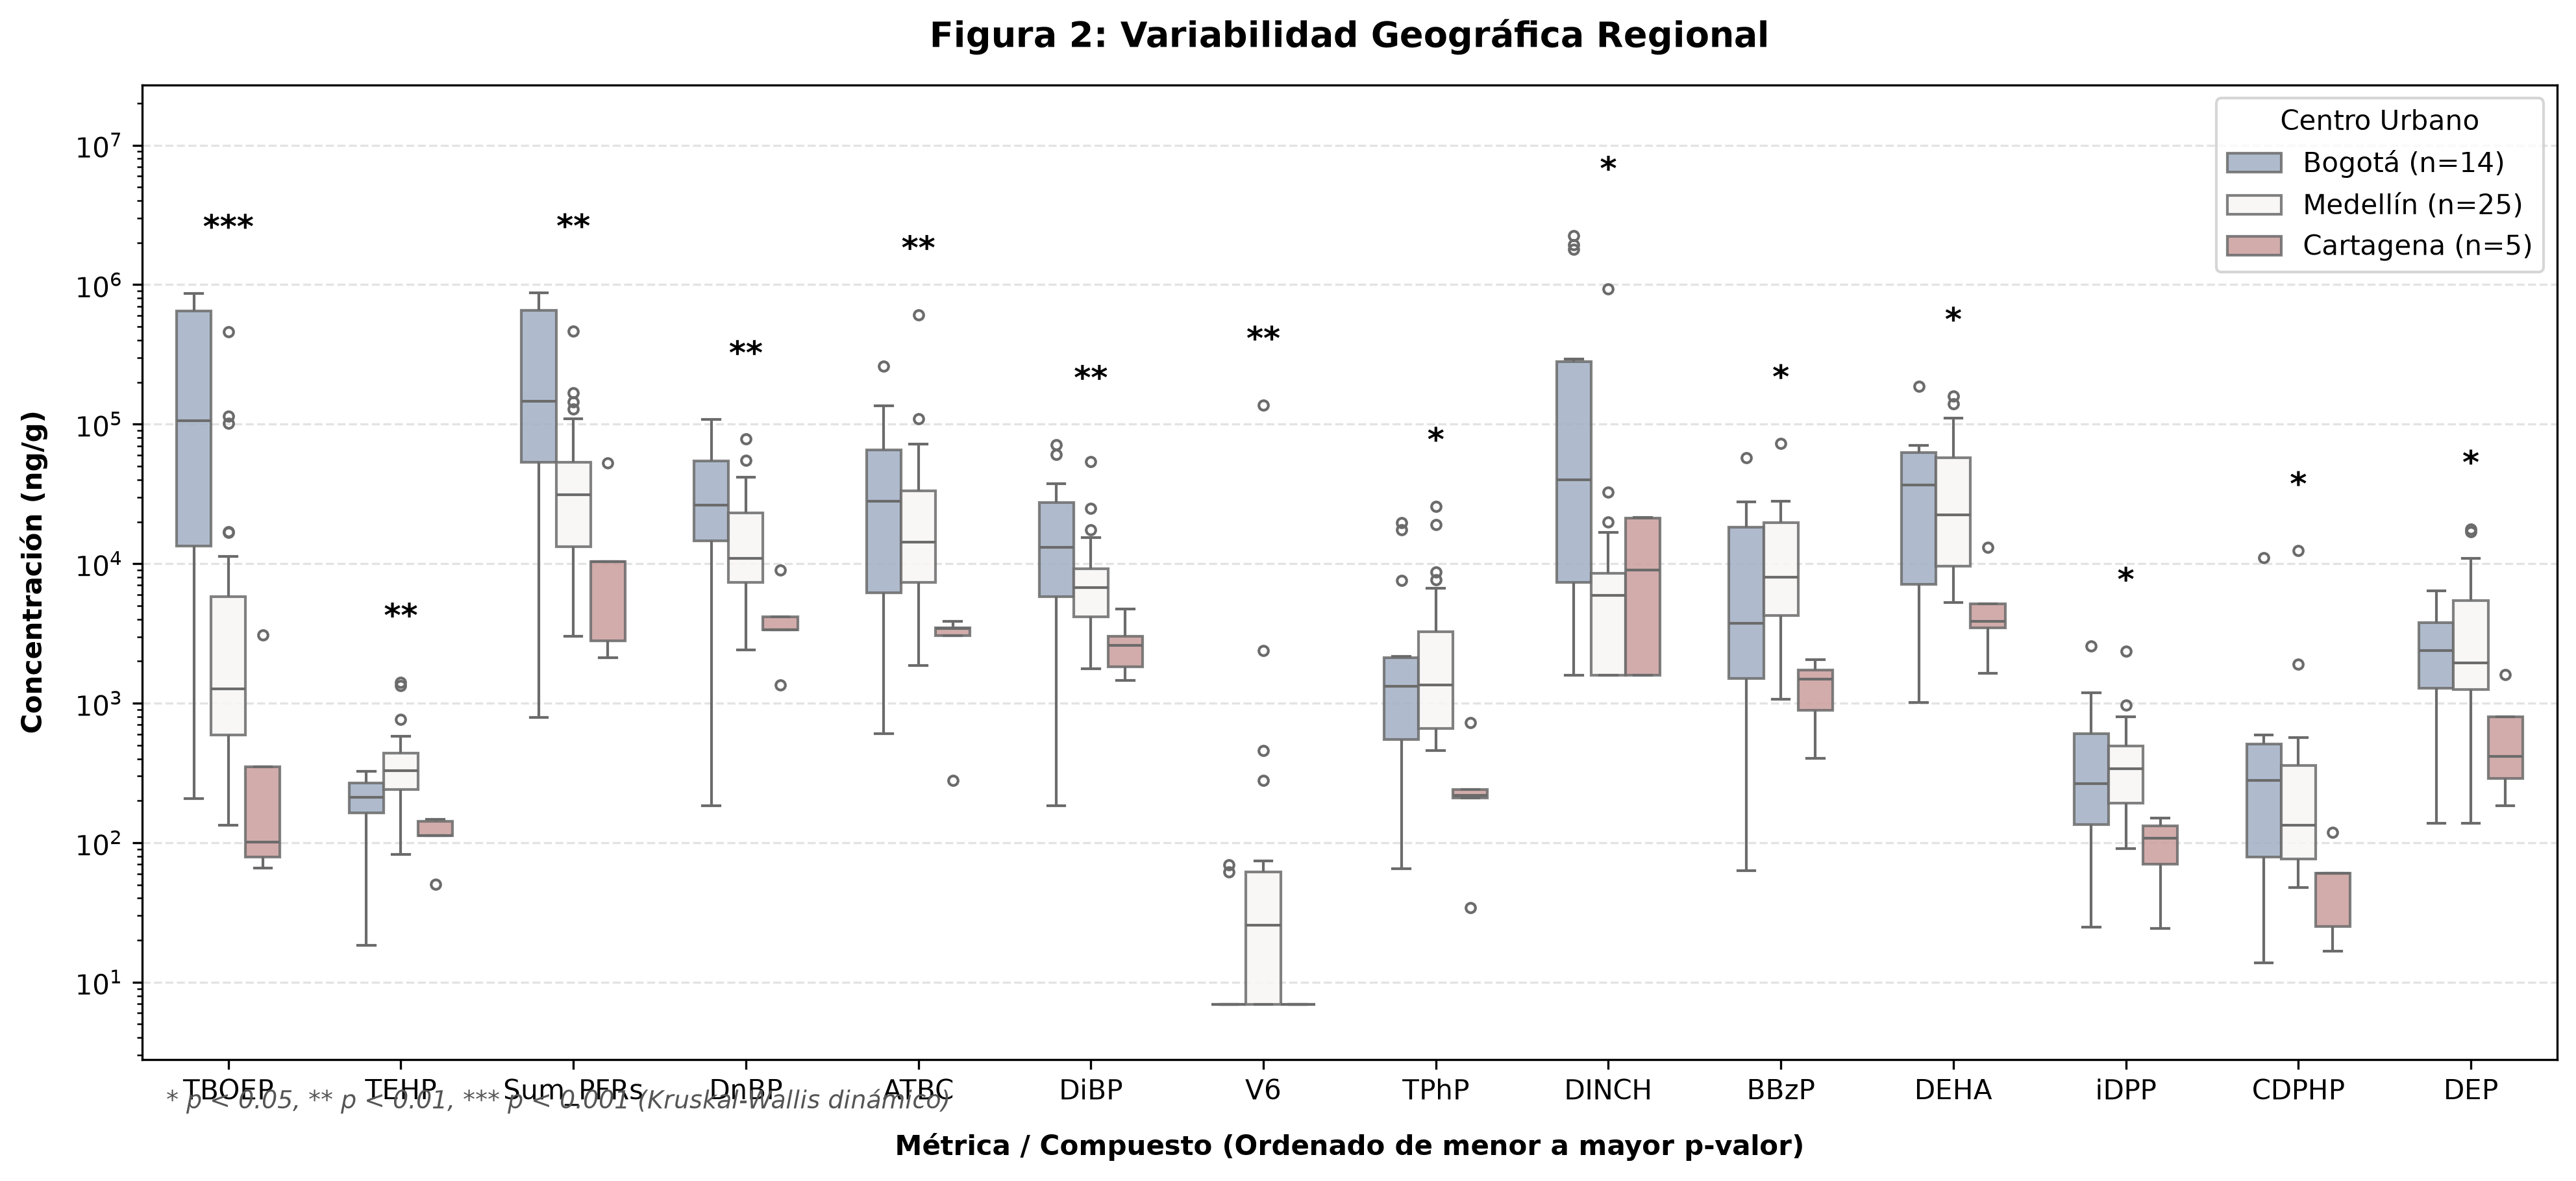

Figura 2 guardada exitosamente en: ../05_Analisis_Reproducible/outputs/figuras/figura_2_gradiente_geografico.png


In [9]:
# Celda 8: Generación de la Figura 2 — Gradiente Geográfico Regional
# 1. Extracción dinámica de las 14 variables significativas ordenadas por p-valor
df_sig_geo = df_res_geo[df_res_geo['p_val'] < 0.05].sort_values(by='p_val').copy()
sig_vars_ordered = df_sig_geo['Variable'].tolist()

# Mapeo dinámico de p-valores directamente desde el DataFrame computado
p_value_dict = dict(zip(df_sig_geo['Variable'], df_sig_geo['p_val']))

# 2. Construcción de matriz larga para Seaborn
df_geo_plot = df_muestras[['sample_id', 'city']].copy()
for var in sig_vars_ordered:
    df_geo_plot[var] = df_muestras[var] if var.startswith('Sum_') else df_conc[var]

df_geo_long = df_geo_plot.melt(
    id_vars=['sample_id', 'city'],
    value_vars=sig_vars_ordered,
    var_name='Compuesto',
    value_name='Concentracion'
)

fig, ax = plt.subplots(figsize=(16, 6.5))

city_order = ['Bogota', 'Medellin', 'Cartagena']
sns.boxplot(
    data=df_geo_long,
    x='Compuesto',
    y='Concentracion',
    hue='city',
    order=sig_vars_ordered,
    hue_order=city_order,
    width=0.6,
    ax=ax,
    boxprops=dict(alpha=0.85),
    fliersize=3.5,
    palette='vlag'
)

# 3. Anotaciones dinámicas de significancia sobre cada caja
for i, var in enumerate(sig_vars_ordered):
    p_val = p_value_dict[var]
    stars = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*"

    max_val = df_geo_long.loc[df_geo_long['Compuesto'] == var, 'Concentracion'].max()
    y_pos = max_val * 2.2

    ax.text(i, y_pos, stars, ha='center', va='bottom', fontsize=12, fontweight='bold')

# 4. Formato de ejes y leyenda
min_val = df_geo_long['Concentracion'].replace(0, np.nan).min()
ax.set_yscale('log')
ax.set_ylim(bottom=min_val * 0.4, top=df_geo_long['Concentracion'].max() * 12)
ax.set_title('Figura 2: Variabilidad Geográfica Regional', fontsize=13, fontweight='bold', pad=14)
ax.set_xlabel('Métrica / Compuesto (Ordenado de menor a mayor p-valor)', fontweight='bold', labelpad=10)
ax.set_ylabel('Concentración (ng/g)', fontweight='bold', labelpad=10)
ax.grid(axis='y', linestyle='--', alpha=0.35)

handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles[:3], ['Bogotá (n=14)', 'Medellín (n=25)', 'Cartagena (n=5)'],
    title='Centro Urbano', loc='upper right', frameon=True, fontsize=10
)

fig.text(
    0.01, -0.05, '* p < 0.05, ** p < 0.01, *** p < 0.001 (Kruskal-Wallis dinámico)',
    transform=ax.transAxes, fontsize=9, style='italic', color='#555555'
)

fig2_path = os.path.join(OUT_FIGS, 'figura_2_gradiente_geografico.png')
plt.savefig(fig2_path)
plt.savefig(os.path.join(OUT_FIGS, 'figura_2_geografica_completa.png'))
plt.show()
print(f"Figura 2 guardada exitosamente en: {fig2_path}")

## 5.2 Figura 3: Contraste Residencial Controlado en Hogares (Bogotá vs Medellín)
En la Figura 3 se aíslan exclusivamente los **hogares residenciales** ($n_{\text{Bogotá}} = 14$ vs $n_{\text{Medellín}} = 10$).

Se grafican:
- Los cuatro analitos y sumatorias estadísticamente significativos en viviendas: **TBOEP** ($p = 0.0109$), $\Sigma\text{PFRs}$ ($p = 0.0242$), **TEHP** ($p = 0.0376$) y **DINCH** ($p = 0.0496$).
- Sumatorias adicionales para contexto de balance de masa: $\Sigma\text{APs}$ y $\Sigma\text{PHs}$.
- Un **control negativo metodológico: TCIPP** ($p = 0.6187$). TCIPP es el retardante de llama universalmente empleado en las espumas flexibles de poliuretano de colchones y cojinería residencial. Las distribuciones de TCIPP entre Bogotá y Medellín resultan idénticas en escala logarítmica, demostrando que las marcadas discrepancias observadas en TBOEP y DINCH no son artefactos aleatorios del muestreo, sino divergencias derivadas de patrones de consumo de ceras de piso y productos plásticos.

### Mecanismo Físico de Partición y Temperatura
De acuerdo con la ecuación integrada de Clausius-Clapeyron:
$$\ln\left(\frac{P_2}{P_1}\right) = -\frac{\Delta H_{\text{vap}}}{R} \left(\frac{1}{T_2} - \frac{1}{T_1}\right)$$
la menor temperatura ambiental de Bogotá ($14^\circ\text{C}$ vs $22^\circ\text{C}$ en Medellín) disminuye la presión de vapor de saturación de los semivolátiles intermedios, favoreciendo su condensación y partición neta hacia la fase sólida del polvo sedimentado según el modelo de equilibrio gas-polvo de Weschler-Nazaroff:
$$K_{\text{dust}} = \frac{C_{\text{polvo}}}{C_{\text{gas}}} \approx f_{\text{om}} \left(\frac{\rho_{\text{oct}}}{\rho_{\text{dust}}}\right) K_{\text{oa}}$$

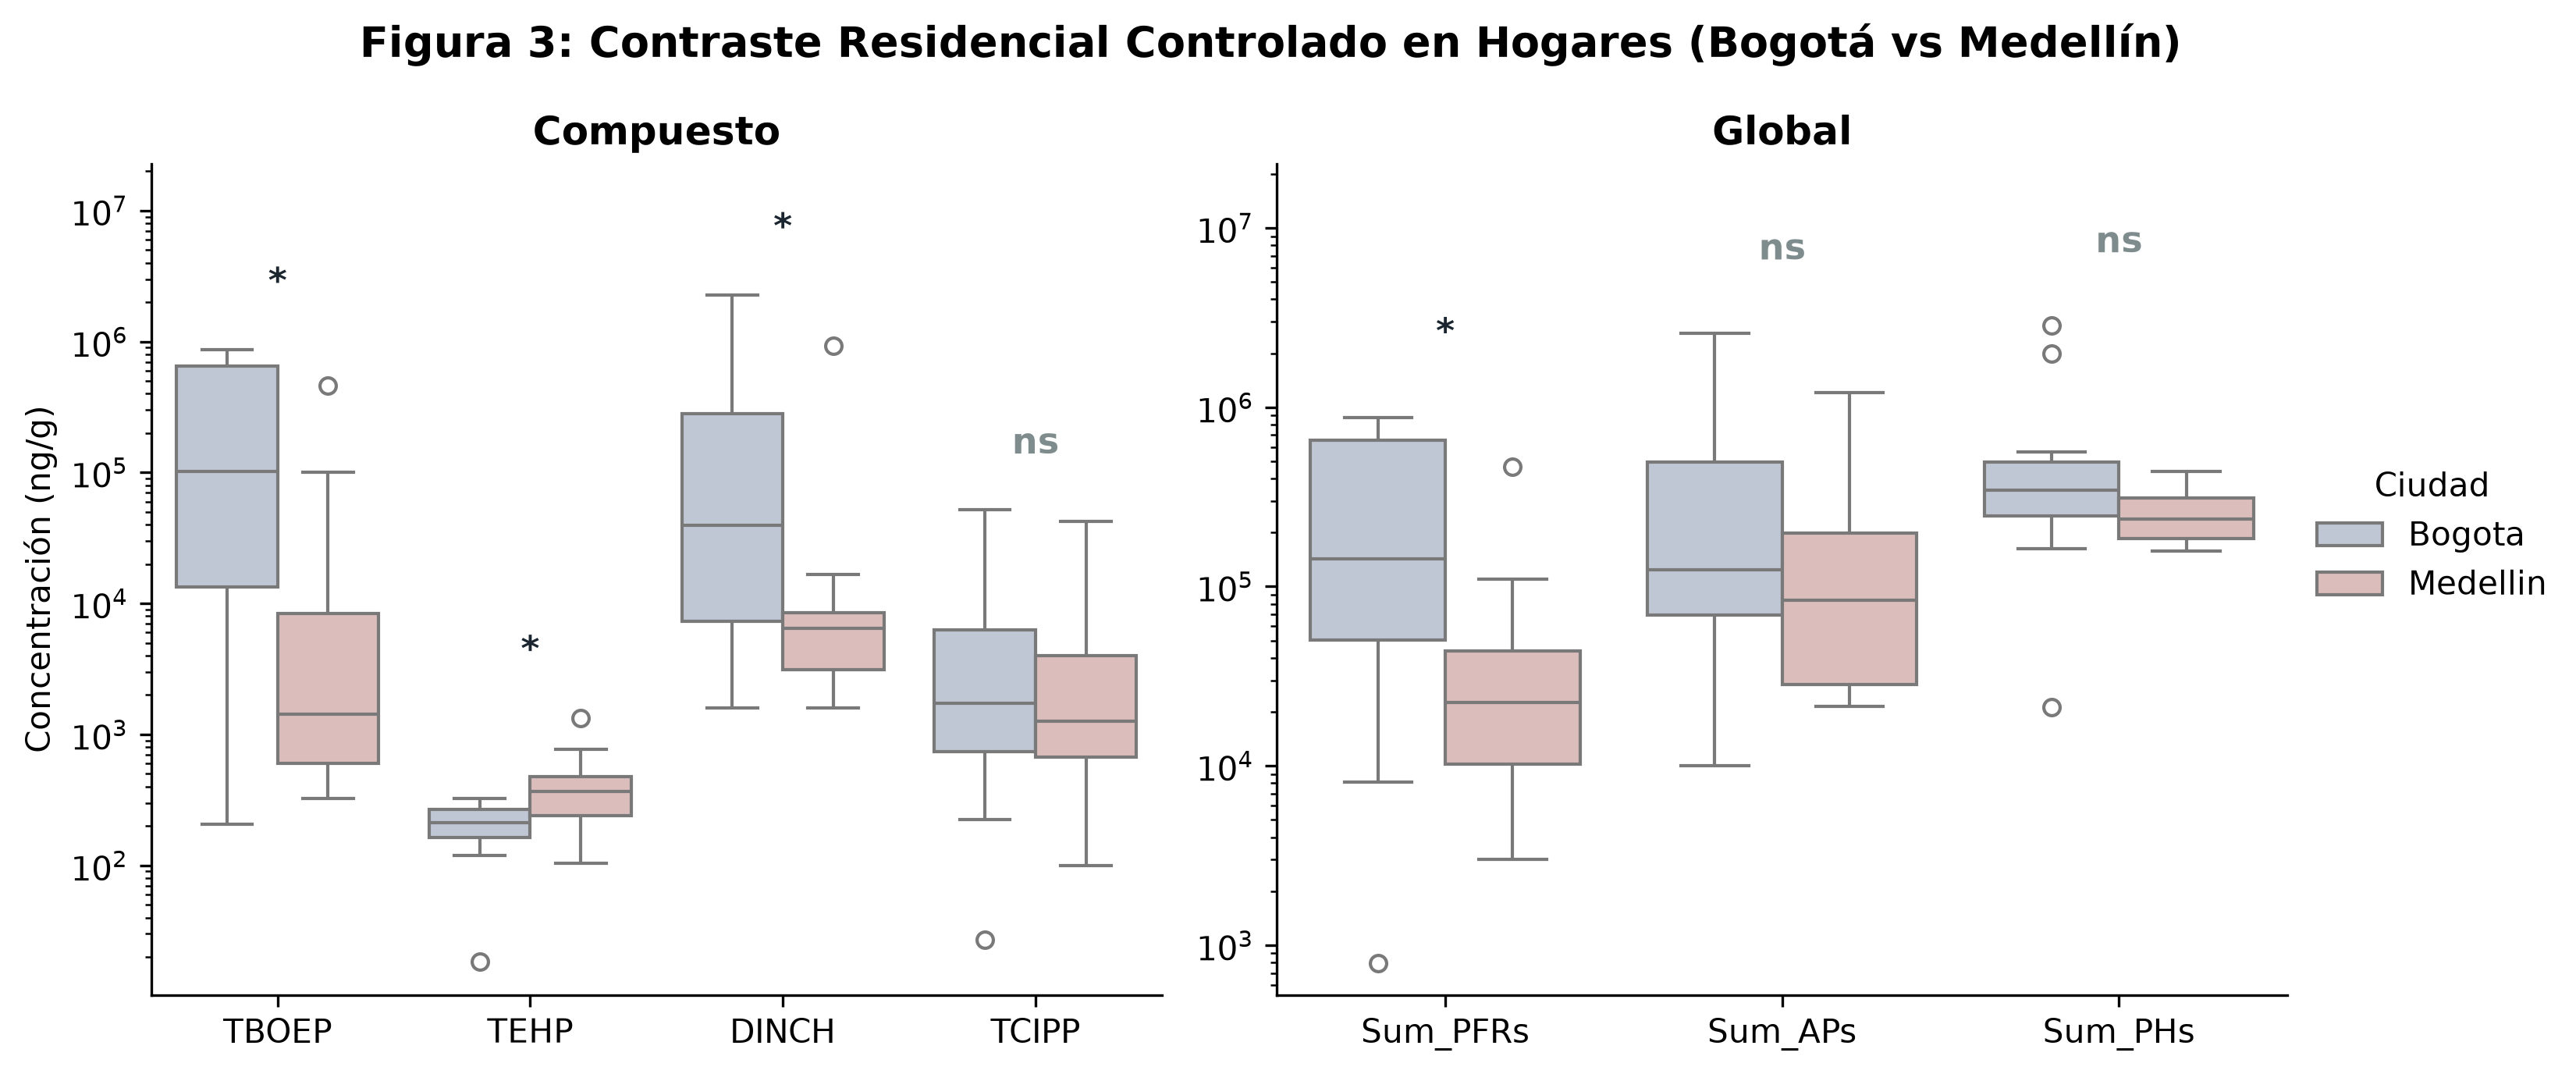

Figura 3 guardada exitosamente en: ../05_Analisis_Reproducible/outputs/figuras/figura_3_contraste_residencial_hogares.png


In [10]:
# Celda 9: Generación de la Figura 3 — Contraste Residencial Controlado en Hogares
target_home = ["TBOEP", "TEHP", "DINCH", "TCIPP", "Sum_PFRs", "Sum_APs", "Sum_PHs"]
df_homes = df_muestras[df_muestras["microenvironment"] == "House"].copy()
df_homes_conc = df_conc.loc[df_homes.index].copy()

df_h_plot = df_homes[["sample_id", "city"]].copy()
for var in target_home:
    df_h_plot[var] = df_homes[var] if var.startswith("Sum_") else df_homes_conc[var]

df_h_long = df_h_plot.melt(
    id_vars=["sample_id", "city"],
    value_vars=target_home,
    var_name="Compuesto",
    value_name="Concentracion"
)

df_h_long["Grupo"] = df_h_long["Compuesto"].map(lambda x: "Compuesto" if x in fam_map else "Global")

city_order = ["Bogota", "Medellin"]
g = sns.catplot(
    data=df_h_long,
    x="Compuesto",
    y="Concentracion",
    col="Grupo",
    kind="box",
    hue="city",
    palette="vlag",
    log_scale=True,
    sharex=False,
    sharey=False
)

g.set_axis_labels("", "Concentración (ng/g)")
g.set_titles(col_template="{col_name}", size=12, weight="bold")

# Mapeo dinámico de p-valores desde df_res_homes
p_map = dict(zip(df_res_homes['Variable'], df_res_homes['p_val']))

# Anotar automáticamente los asteriscos de significancia
for ax in g.axes.flat:
    labels = [tick.get_text() for tick in ax.get_xticklabels()]

    for i, var in enumerate(labels):
        p_val = p_map.get(var, 1.0)
        label_sig = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*" if p_val < 0.05 else "ns"
        max_val = df_h_long.loc[df_h_long["Compuesto"] == var, "Concentracion"].max()
        y_pos = max_val * 2.3
        color_label = "#1A252F" if label_sig != "ns" else "#7F8C8D"

        ax.text(
            i, y_pos, label_sig,
            ha="center", va="bottom",
            fontsize=11, fontweight="bold", color=color_label
        )

# Corrección de advertencia: límites positivos en escala logarítmica
min_pos_val = df_h_long["Concentracion"].replace(0, np.nan).min()
for ax in g.axes.flat:
    current_ymin, _ = ax.get_ylim()
    new_ymin = max(current_ymin, min_pos_val * 0.3)
    new_ymax = df_h_long["Concentracion"].max() * 8
    ax.set_ylim(bottom=new_ymin, top=new_ymax)

g.fig.subplots_adjust(top=0.86, bottom=0.15)
g.fig.suptitle("Figura 3: Contraste Residencial Controlado en Hogares (Bogotá vs Medellín)", fontsize=13, weight="bold")
g._legend.set_title("Ciudad")

fig3_path = os.path.join(OUT_FIGS, 'figura_3_contraste_residencial_hogares.png')
g.savefig(fig3_path)
plt.show()
print(f"Figura 3 guardada exitosamente en: {fig3_path}")